# Questions - Recursive Self Improvement Triton kernel agent

1. What happened with iter6?

2. Why is layer 0 different than other layers?

3. why is int8 Kernel working on synthetic keys, but not real keys? where does the program specification fail here?

4. What are gate keys?

5. Why is phase 2 best on layer 0 gate keys? but worse than iter6 on the rest of the keys?

## Terminology:
- Iter6: The sixth iteration of the kernel improvement process for improvement process 1 (20261026-004515)
- Iter14: The fourteenth iteration of the kernel improvement process for improvement process 2 (20261026-033411)
- synthetic keys: random guassian vector embeddings
- gate keys: Real post-RoPE keys from Qwen2.5-1.5B-Instruct's KV cache, called "gate keys" because phase 2 recursive improvement needed them to avoid int8 kernel failure. I.e it was a missing specification.
- layer 0: refers to what?


## Look at Qwen's layer-0 keys yourself

Runs Qwen2.5-1.5B-Instruct (the model the gate and held-out keys came from) on this Mac, MPS if available, else CPU.
It does one **prefill** of a long prompt and pulls the post-RoPE keys out of the KV cache. That's the same moment
Double-P builds its cluster index (`RetroClusterIndex.build`), which is where the k-means kernel runs.

The key files had 32,768 keys per row: two separate ~16K-token prompts concatenated, topped up from a third, not one
32K prompt. Here one prompt of `N_TOKENS` is enough to see the effect. Qwen2.5 has no 5B; `MODEL` takes the 3B or 7B
too, just slower.

Needs: `pip install transformers matplotlib` (torch is already in this kernel).

In [1]:
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import transformers
from packaging.version import Version
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
N_TOKENS = 4096  # prompt length; the key files used ~16K-token prompts (try 16384 if memory allows)
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
DTYPE = torch.bfloat16 if DEVICE == "mps" else torch.float32
torch.set_grad_enabled(False)

tok = AutoTokenizer.from_pretrained(MODEL)
dtype_kw = "dtype" if Version(transformers.__version__) >= Version("4.56") else "torch_dtype"
model = AutoModelForCausalLM.from_pretrained(MODEL, **{dtype_kw: DTYPE}).to(DEVICE).eval()
cfg = model.config
L, KVH = cfg.num_hidden_layers, cfg.num_key_value_heads
print(f"{DEVICE}: {L} layers, {cfg.num_attention_heads} query heads, {KVH} kv heads, "
      f"head dim {cfg.hidden_size // cfg.num_attention_heads}")

/Users/nohren/miniconda3/envs/torch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mps: 28 layers, 12 query heads, 2 kv heads, head dim 128


In [2]:
# the book the key files used (Pride and Prejudice, Project Gutenberg); any long English text works
book = Path("pride_and_prejudice.txt")
if not book.exists():
    urllib.request.urlretrieve("https://www.gutenberg.org/cache/epub/1342/pg1342.txt", book)
text = book.read_text(encoding="utf-8")
text = text[text.find("\n", text.find("*** START")) + 1:]  # skip the Gutenberg header
body = tok.decode(tok(text, add_special_tokens=False).input_ids[: N_TOKENS - 64])
prompt = tok.apply_chat_template([{"role": "user", "content": body + "\n\nSummarize the text above."}],
                                 add_generation_prompt=True, tokenize=False)
ids = tok(prompt, add_special_tokens=False, return_tensors="pt").input_ids.to(DEVICE)
print(ids.shape[1], "prompt tokens")

Token indices sequence length is longer than the specified maximum sequence length for this model (175672 > 131072). Running this sequence through the model will result in indexing errors


4067 prompt tokens


In [12]:
# this data is a specification to the agent of what data it will see and what is is optimizing against. needs to be 100% correct

# Double-P's index build (sparse_attention/index/cluster/retro_cluster.py, RetroClusterIndex.build) clusters only the
# middle of the prompt: the first static_start tokens (sinks) and the last static_end tokens (recent window) stay
# exact, and the rest is mean-centered per kv head before segment_k_means. This cell does the same for two disjoint
# stretches of the book, runs Double-P's k-means on the rows the kernel agent uses, and writes the gate and held-out
# key files in the format the harness loads (keys [8, 32768, 128] bf16, unit centroids [8, 2048, 128] bf16, rows).
SINK, WINDOW = 4, 64  # config/Llama-3.1-8B-Instruct.json static_start / static_end
N_KEYS = 32768  # keys per row after stripping: the agent's final-32K shape
PROMPT_LEN = SINK + N_KEYS + WINDOW
N_CENT, N_SEG = 2048, 4  # what benchmark/config.py gives for this prompt length (~16 keys/cluster, 1 segment/8192)
CHUNK = 1024  # chunked prefill: same keys as one pass, but attention memory ~CHUNK x PROMPT_LEN instead of PROMPT_LEN^2
OUT = Path("centered")  # new files go here, next to (not over) the old raw-key files
SETS = {  # different text and different (layer, kv head) rows, alternating heads as before
    "gate": {"offset": 0, "rows": [(0, 0), (3, 1), (7, 0), (11, 1), (15, 0), (19, 1), (23, 0), (27, 1)]},
    "heldout": {"offset": 80_000, "rows": [(0, 1), (2, 0), (6, 1), (10, 0), (14, 1), (18, 0), (22, 1), (26, 0)]},
}

book_ids = tok(text, add_special_tokens=False).input_ids
MARK = "<<BODY>>"
pre, post = tok.apply_chat_template([{"role": "user", "content": MARK + "\n\nSummarize the text above."}],
                                    add_generation_prompt=True, tokenize=False).split(MARK)
pre_ids, post_ids = tok(pre, add_special_tokens=False).input_ids, tok(post, add_special_tokens=False).input_ids


def prompt_ids(offset):
    # chat-formatted prompt of exactly PROMPT_LEN tokens around book tokens starting at offset
    body = book_ids[offset: offset + PROMPT_LEN - len(pre_ids) - len(post_ids)]
    ids = torch.tensor([pre_ids + body + post_ids], device=DEVICE)
    assert ids.shape[1] == PROMPT_LEN, ids.shape
    return ids


def prefill_keys(ids):
    # post-RoPE keys of every layer, [L, KVH, tokens, head dim]; model.model skips the vocab projection
    cache = None
    for s in range(0, ids.shape[1], CHUNK):
        cache = model.model(input_ids=ids[:, s: s + CHUNK], past_key_values=cache, use_cache=True).past_key_values
    if DEVICE == "mps":
        torch.mps.synchronize()

    def layer_keys(i):  # the cache API differs across transformers versions
        if hasattr(cache, "layers"):
            return cache.layers[i].keys[0]
        if hasattr(cache, "key_cache"):
            return cache.key_cache[i][0]
        return cache[i][0][0]

    return torch.stack([layer_keys(i).float().cpu() for i in range(L)])


def kmeans_input(k):
    # retro_cluster.py: kmeans_keys = keys[:, valid_start + static_start : seq_len - static_end], minus their mean
    k = k[..., SINK: k.shape[-2] - WINDOW, :]
    return k - k.mean(dim=-2, keepdim=True)


def assign_update(data, cent, normalize):
    # one Lloyd step with the semantics of _triton_assign_kernel + _triton_update_kernel
    idx = (data @ cent.transpose(1, 2)).argmax(-1)
    b, c, d = cent.shape
    sums = torch.zeros(b, c, d).scatter_add_(1, idx[..., None].expand(-1, -1, d), data)
    cnt = torch.zeros(b, c).scatter_add_(1, idx, torch.ones(idx.shape))
    new = sums / cnt.clamp(min=1)[..., None]
    if normalize:
        new = new / new.norm(dim=-1, keepdim=True).clamp(min=1e-12)
    return torch.where(cnt[..., None] > 0, new, cent), idx  # empty clusters keep their old centroid


def segment_k_means(key, num_c, num_seg, iters=10):
    # key [N, d] for one head; returns the final-pass labels and the centroids that pass scores against
    n, d = key.shape
    ci = (torch.arange(num_c, dtype=torch.float32) * (n / num_c) + n / num_c / 2).long()  # evenly spaced keys
    cent = key[ci].clone().reshape(num_seg, num_c // num_seg, d)
    data = key[: n // num_seg * num_seg].reshape(num_seg, -1, d)
    for _ in range(iters - 1):
        cent, _ = assign_update(data, cent, normalize=True)
    cent = cent.reshape(1, num_c, d)
    _, idx = assign_update(key[None], cent, normalize=False)
    return idx[0], cent[0]


OUT.mkdir(exist_ok=True)
for name, spec in SETS.items():
    t0 = time.time()
    k_all = kmeans_input(prefill_keys(prompt_ids(spec["offset"])))  # [L, KVH, N_KEYS, d]
    print(f"{name}: book tokens {spec['offset']:,}+, prefill {time.time() - t0:.0f} s, keys {tuple(k_all.shape)}")
    row_keys, row_cents = [], []
    for layer, h in spec["rows"]:
        k = k_all[layer, h].bfloat16().float()  # the kernel's input is bf16
        lab, cent = segment_k_means(k, N_CENT, N_SEG)
        norm = cent.norm(dim=1)
        not_unit = int(((norm - 1).abs() > 1e-3).sum())  # empty clusters that kept their unnormalized starting key
        biggest = torch.bincount(lab, minlength=N_CENT).max().item() / N_KEYS
        print(f"  layer {layer:2d} head {h}: |k| median {k.norm(dim=1).median():5.1f}, biggest cluster {biggest:.2%}, "
              f"centroids not unit length {not_unit}")
        row_keys.append(k.bfloat16())
        row_cents.append((cent / norm[:, None]).bfloat16())  # the harness's error bound assumes unit centroids
    path = OUT / f"real_keys_{name}.pt"
    torch.save({"keys": torch.stack(row_keys), "cent": torch.stack(row_cents), "rows": spec["rows"],
                "prompts": f"pride_and_prejudice tokens {spec['offset']}+, {PROMPT_LEN}-token chat prompt",
                "model": f"{MODEL} post-RoPE keys, first {SINK} and last {WINDOW} tokens dropped, mean-centered"}, path)
    print(f"  saved {path} ({path.stat().st_size / 1e6:.0f} MB)")
    if name == "gate":
        keys = k_all  # the cells below look at the gate prompt's centered keys
    del k_all


gate: book tokens 0+, prefill 64 s, keys (28, 2, 32768, 128)
  layer  0 head 0: |k| median  26.1, biggest cluster 0.32%, centroids not unit length 0
  layer  3 head 1: |k| median  16.5, biggest cluster 0.17%, centroids not unit length 0
  layer  7 head 0: |k| median  16.7, biggest cluster 0.21%, centroids not unit length 0
  layer 11 head 1: |k| median  19.2, biggest cluster 0.19%, centroids not unit length 0
  layer 15 head 0: |k| median  17.7, biggest cluster 0.15%, centroids not unit length 0
  layer 19 head 1: |k| median  16.4, biggest cluster 0.12%, centroids not unit length 0
  layer 23 head 0: |k| median  18.2, biggest cluster 0.14%, centroids not unit length 0
  layer 27 head 1: |k| median  16.1, biggest cluster 0.19%, centroids not unit length 0
  saved centered/real_keys_gate.pt (71 MB)
heldout: book tokens 80,000+, prefill 46 s, keys (28, 2, 32768, 128)
  layer  0 head 1: |k| median  29.0, biggest cluster 0.16%, centroids not unit length 0
  layer  2 head 0: |k| median  16.0

### What makes layer 0 different

Per (layer, kv head):
- **median |k|**: key length.
- **cos(k, mean k)**: how closely each key points along the head's mean key. 1.00 means every key points the same way.
- **mean share**: fraction of the keys' energy (|k|²) that sits in that shared mean part.
- **crest**: largest entry / RMS entry per key. int8 quantization rounds each key on a step set by its largest entry,
  so a high crest leaves the small entries with few levels (synthetic Gaussian keys: ~2.8).
- **|k_proj bias|**: length of the key projection's bias for that head. Qwen2 adds a bias to K. If it's about as long
  as the keys, the bias is the shared part. RoPE rotates it with position, so this is a rough check, not proof.

In [9]:
#per head row stats
def row_stats(k):
    mean = k.mean(0) # median magnitude of keys in head
    cos = (k @ mean / (k.norm(dim=1) * mean.norm())).mean().item()
    share = (mean.norm() ** 2 / k.pow(2).sum(1).mean()).item()
    crest = (k.abs().amax(1) / k.pow(2).mean(1).sqrt()).median().item()
    return k.norm(dim=1).median().item(), cos, share, crest


attn = model.model.layers
print(f"{'layer':>5} {'head':>4} {'median |k|':>10} {'|k_proj bias|':>13} {'cos(k, mean k)':>14} {'mean share':>10} "
      f"{'crest':>5} {'crest centered':>14}")
for layer in range(L):
    bias = attn[layer].self_attn.k_proj.bias.float().view(KVH, -1).norm(dim=1).cpu()
    for h in range(KVH):
        k = keys[layer, h]
        norm, cos, share, crest = row_stats(k)
        crest_c = row_stats(k - k.mean(0))[3]
        print(f"{layer:5d} {h:4d} {norm:10.1f} {bias[h]:13.1f} {cos:14.2f} {share:10.2f} {crest:5.1f} {crest_c:14.1f}")

layer head median |k| |k_proj bias| cos(k, mean k) mean share crest crest centered
    0    0       18.1         821.2           0.09       0.01   3.7            3.7
    0    1       18.8         736.0           0.06       0.00   3.7            3.7
    1    0       23.3         153.5           0.01       0.00   6.3            6.3
    1    1       17.1          23.2           0.00       0.00   3.0            3.0
    2    0       14.6           9.8           0.00       0.00   3.0            3.0
    2    1       15.2          31.6           0.00       0.00   3.1            3.1
    3    0       17.0          10.6          -0.00       0.00   3.0            3.0
    3    1       14.3           9.5           0.00       0.00   3.0            3.0
    4    0       13.5           7.5          -0.00       0.00   3.0            3.0
    4    1       15.9           7.4           0.00       0.00   2.9            2.9
    5    0       12.4           6.4           0.00       0.00   3.1            3.1
    

### What layer-0 keys look like

Top row: the keys as cached. Bottom row: the same keys minus the head's mean key, which is what Double-P actually
clusters (`retro_cluster.py`: `segment_k_means(key=kmeans_keys - mean_key, ...)`). Each panel has its own color scale,
printed in its title.

The line plot shows which dimensions carry the shared part. Qwen's RoPE rotates dim i together with dim i + 64, and
the rotation slows as i grows: the last pairs (around dims 55-63 and 119-127) turn by well under a radian over 32K
tokens. A bias that sits in those dims survives RoPE almost unchanged, so every token's key gets the same big vector.

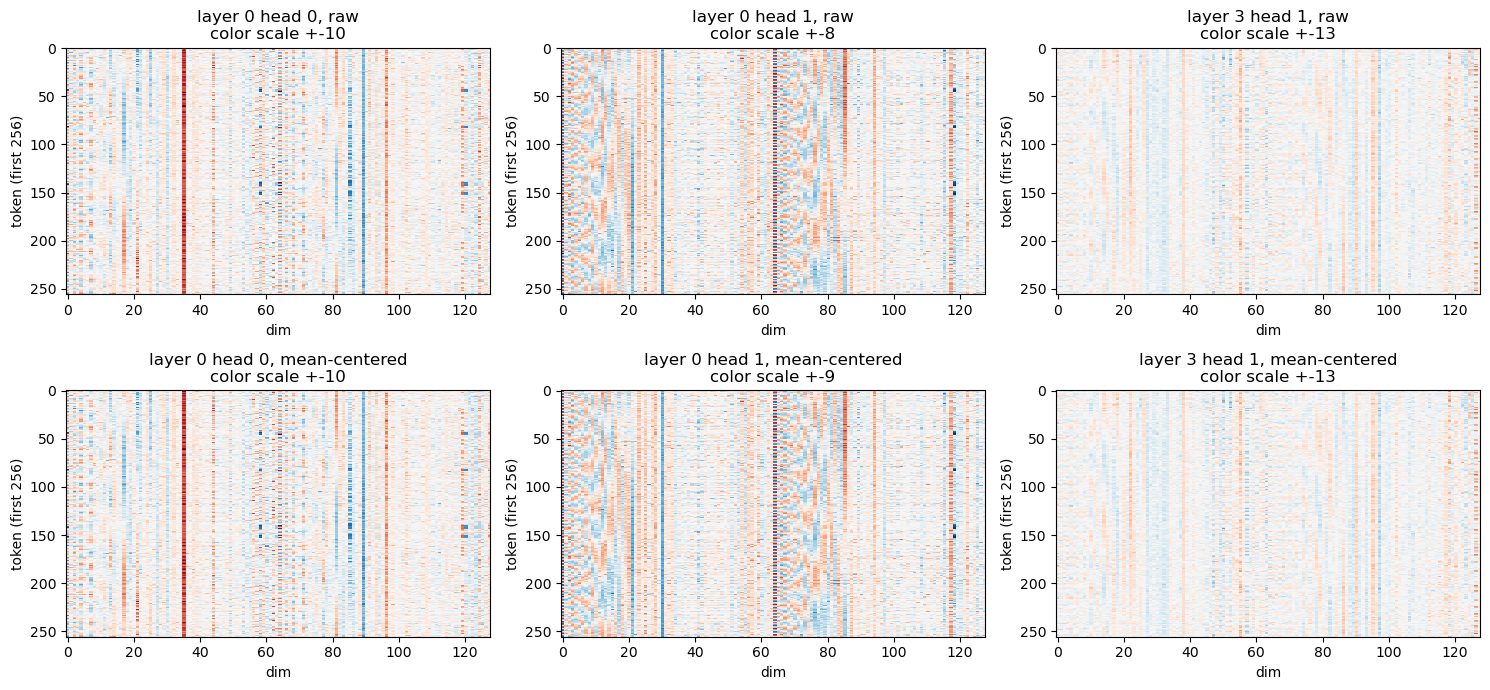

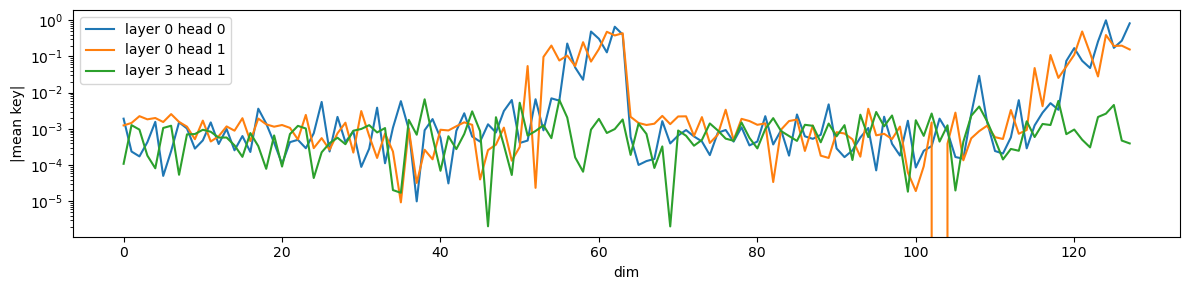

In [10]:
ROWS = [(0, 0), (0, 1), (3, 1)]  # (layer, kv head): the two layer-0 heads, and the gate's first normal row
fig, ax = plt.subplots(2, len(ROWS), figsize=(5 * len(ROWS), 7))
for col, (layer, h) in enumerate(ROWS):
    k = keys[layer, h]
    for row, (name, m) in enumerate([("raw", k[:256]), ("mean-centered", (k - k.mean(0))[:256])]):
        v = m.abs().max().item()
        ax[row, col].imshow(m, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v, interpolation="nearest")
        ax[row, col].set(title=f"layer {layer} head {h}, {name}\ncolor scale +-{v:.0f}", xlabel="dim",
                         ylabel="token (first 256)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 3))
for layer, h in ROWS:
    plt.semilogy(keys[layer, h].mean(0).abs(), label=f"layer {layer} head {h}")
plt.xlabel("dim")
plt.ylabel("|mean key|")
plt.legend()
plt.tight_layout()
plt.show()

### Does the kernel see the skew?

Runs Double-P's own clustering on each row, raw and mean-centered. It's a CPU copy of `segment_k_means` in
`sparse_attention/index/cluster/kmeans.py`, with cluster counts from `benchmark/config.py` (~16 keys per cluster,
one segment per 8,192 tokens) and the first 4 and last 64 tokens left out as in the config. Then it counts what the
kernel's atomic adds would hit:
- **biggest cluster**: share of keys in the largest cluster. When it's large, most adds go to one address and queue.
- **distinct labels per 128-key tile**: 128 keys is one block of the kernel. Synthetic keys give ~124; the earlier
  measurement on normal real rows was 17–35.
- **unit centroids**: how many centroids ended up unit length. Empty clusters keep their starting key unnormalized.

In [6]:
SINK, WINDOW = 4, 64  # config/Llama-3.1-8B-Instruct.json static_start / static_end: never clustered


def num_clusters_and_segments(context_len, cluster_size=16):
    # same rounding as benchmark/config.py
    n_seg = max(1, context_len // 8192)
    n = -(-context_len // cluster_size)
    lower = (n // (n_seg * 32)) * (n_seg * 32)
    upper = lower + n_seg * 32
    n = lower if abs(n - lower) <= abs(n - upper) else upper
    return max(n, n_seg * 32), n_seg


def assign_update(data, cent, normalize):
    # one Lloyd step with the semantics of _triton_assign_kernel + _triton_update_kernel
    idx = (data @ cent.transpose(1, 2)).argmax(-1)
    b, c, d = cent.shape
    sums = torch.zeros(b, c, d).scatter_add_(1, idx[..., None].expand(-1, -1, d), data)
    cnt = torch.zeros(b, c).scatter_add_(1, idx, torch.ones(idx.shape))
    new = sums / cnt.clamp(min=1)[..., None]
    if normalize:
        new = new / new.norm(dim=-1, keepdim=True).clamp(min=1e-12)
    return torch.where(cnt[..., None] > 0, new, cent), idx  # empty clusters keep their old centroid


def segment_k_means(key, num_c, num_seg, iters=10):
    # key [N, d] for one head; returns the final-pass labels and the centroids that pass scored against
    n, d = key.shape
    ci = (torch.arange(num_c, dtype=torch.float32) * (n / num_c) + n / num_c / 2).long()  # evenly spaced keys
    cent = key[ci].clone().reshape(num_seg, num_c // num_seg, d)
    data = key[: n // num_seg * num_seg].reshape(num_seg, -1, d)
    for _ in range(iters - 1):
        cent, _ = assign_update(data, cent, normalize=True)
    cent = cent.reshape(1, num_c, d)
    _, idx = assign_update(key[None], cent, normalize=False)
    return idx[0], cent[0]


num_c, num_seg = num_clusters_and_segments(keys.shape[2])
print(f"{keys.shape[2]} tokens -> {num_c} clusters in {num_seg} segment(s)")
for layer, h in ROWS:
    k = keys[layer, h, SINK: keys.shape[2] - WINDOW]
    for name, kk in [("raw", k), ("mean-centered", k - k.mean(0))]:
        lab, cent = segment_k_means(kk, num_c, num_seg)
        biggest = torch.bincount(lab, minlength=num_c).max().item() / lab.numel()
        tiles = lab[: lab.numel() // 128 * 128].view(-1, 128)
        distinct = torch.tensor([t.unique().numel() for t in tiles]).float()
        unit = int(((cent.norm(dim=1) - 1).abs() < 1e-3).sum())
        print(f"layer {layer:2d} head {h} {name:13s} biggest cluster {biggest:6.1%} | distinct labels per tile: "
              f"median {distinct.median():3.0f}, min {distinct.min():3.0f} | unit centroids {unit}/{num_c}")

4067 tokens -> 256 clusters in 1 segment(s)
layer  0 head 0 raw           biggest cluster  44.1% | distinct labels per tile: median   5, min   2 | unit centroids 46/256
layer  0 head 0 mean-centered biggest cluster   1.2% | distinct labels per tile: median  22, min  13 | unit centroids 256/256
layer  0 head 1 raw           biggest cluster  83.9% | distinct labels per tile: median   3, min   2 | unit centroids 253/256
layer  0 head 1 mean-centered biggest cluster   0.7% | distinct labels per tile: median  11, min   9 | unit centroids 256/256
layer  3 head 1 raw           biggest cluster   1.6% | distinct labels per tile: median  14, min  11 | unit centroids 256/256
layer  3 head 1 mean-centered biggest cluster   1.3% | distinct labels per tile: median  15, min  12 | unit centroids 256/256


In [40]:
# testing the indices 
K = torch.arange(6).resize(3,2)
C = torch.arange(6,10).resize(2,2)

max_val = torch.zeros(3)
max_idx = torch.zeros(3)

ip = K @ C
print('k * c affinity')
print(ip)

print('each k index points to its correspoding centroid')
tmp_max_val, tmp_max_idx = torch.max(ip, dim=1)
print('tmp_max_val, tmp_max_idx', tmp_max_val, tmp_max_idx)

print('max_val before update')
print(max_val)
# condition for values that tmp_max_val > max_val
#   then fill values with tmp_max_idx, else fill with max_idx
# 
#   this is the if condition that fills tensor by tensor for K chunks
#   with only the argmax centroid
#   notice this exists because for every centroid we are iterating through all K chunks
# vectorized if/else statement
max_idx = torch.where(tmp_max_val > max_val, tmp_max_idx, max_idx)
max_val = torch.maximum(tmp_max_val, max_val)

print(max_idx, max_val)

# multiply it by offset to get it into global element space that is triton
s_mem = max_idx[:, None] + torch.arange(2).resize(1,2)
print()
print('K matrix')
print(K)
print()
print('s_mem addrs tile')
print(s_mem)
print('see the issue? we are saying for each memory address row in s_mem add row values from K.  ')
print('they are the same addresses, so we need an atomic_add to prevent race conditions')
print('read K from top row to bottom row, each row gets added to corresponding row memory addresses in s_mem')



k * c affinity
tensor([[ 8,  9],
        [36, 41],
        [64, 73]])
each k index points to its correspoding centroid
tmp_max_val, tmp_max_idx tensor([ 9, 41, 73]) tensor([1, 1, 1])
max_val before update
tensor([0., 0., 0.])
tensor([1., 1., 1.]) tensor([ 9., 41., 73.])

K matrix
tensor([[0, 1],
        [2, 3],
        [4, 5]])

s_mem addrs tile
tensor([[1., 2.],
        [1., 2.],
        [1., 2.]])
see the issue? we are saying for each memory address row in s_mem add row values from K.  
they are the same addresses, so we need an atomic_add to prevent race conditions
read K from top row to bottom row, each row gets added to corresponding row memory addresses in s_mem


/Users/nohren/miniconda3/envs/torch/lib/python3.11/site-packages/torch/_tensor.py:1000: UserWarning: non-inplace resize is deprecated
  warnings.warn("non-inplace resize is deprecated")


In [9]:

m = torch.zeros(10,50)

def test_stride(r,c):
    print(r,c)
test_stride(*m.stride())

50 1


In [21]:
(1 + 1/(2**1)*1 + 1/(2**2)*0 + 1/(2**3)*1 + 1/(2**4)*1)  * 2**-1

0.84375

In [50]:
k = 2
base = 2
series = 500
#power of 2 fractions
print(sum([base**-i for i in range(k-1,k)]))

print(sum([base**-i for i in range(k,series)]))

0.5
0.5


In [51]:
2**-12

0.000244140625

In [52]:
2**12

4096

In [53]:
2**-11 > 2**-12

True

In [63]:
import torch

torch.full((6,4), float("-inf"), dtype=torch.bfloat16)

tensor([[-inf, -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf]], dtype=torch.bfloat16)

In [71]:
BLOCK_N=5
BLOCK_K=6

best_reduce = torch.full([BLOCK_N], float("-inf"), dtype=torch.bfloat16)

best = torch.full([BLOCK_N, BLOCK_K], float("-inf"), dtype=torch.bfloat16)

# the memory holders for the max score/index floats
print(best_reduce)
print(best)

ip = torch.randn([BLOCK_N, BLOCK_K], dtype=torch.bfloat16)
print(ip)

# do inside the computation the dimension reduction

best_reduce =torch.maximum(best_reduce, torch.max(ip, dim=1).values)
print(best_reduce)

best = torch.maximum(best, ip)
print(best)


tensor([-inf, -inf, -inf, -inf, -inf], dtype=torch.bfloat16)
tensor([[-inf, -inf, -inf, -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf, -inf, -inf]], dtype=torch.bfloat16)
tensor([[-1.1641,  0.0583, -1.3125,  1.0625, -0.6953,  2.3750],
        [-0.3457, -0.1973,  1.3984, -0.3555,  0.8320,  1.2891],
        [ 1.4609,  0.6562, -1.0547,  0.0187, -0.6836, -1.2578],
        [-1.4062,  0.9297,  0.0405,  0.8633, -0.5977, -0.4980],
        [ 1.4375,  1.0703,  0.5547,  0.1143, -1.0781,  2.2500]],
       dtype=torch.bfloat16)
tensor([2.3750, 1.3984, 1.4609, 0.9297, 2.2500], dtype=torch.bfloat16)
tensor([[-1.1641,  0.0583, -1.3125,  1.0625, -0.6953,  2.3750],
        [-0.3457, -0.1973,  1.3984, -0.3555,  0.8320,  1.2891],
        [ 1.4609,  0.6562, -1.0547,  0.0187, -0.6836, -1.2578],
        [-1.4062,  0.9297,  0.0405,  0.8633, -0.5977, -0.4980],
        [

In [75]:
A = torch.tensor([1, 2, 3])
B = torch.tensor([4, 5, 6])
C = A + B
print(C)
C * 1/3



tensor([5, 7, 9])


tensor([1.6667, 2.3333, 3.0000])

In [82]:
s_ptrs = torch.arange(10)[None, :]

A = torch.arange(10) 
A = A[:,None] * 20

s_ptrs + A

tensor([[  0,   1,   2,   3,   4,   5,   6,   7,   8,   9],
        [ 20,  21,  22,  23,  24,  25,  26,  27,  28,  29],
        [ 40,  41,  42,  43,  44,  45,  46,  47,  48,  49],
        [ 60,  61,  62,  63,  64,  65,  66,  67,  68,  69],
        [ 80,  81,  82,  83,  84,  85,  86,  87,  88,  89],
        [100, 101, 102, 103, 104, 105, 106, 107, 108, 109],
        [120, 121, 122, 123, 124, 125, 126, 127, 128, 129],
        [140, 141, 142, 143, 144, 145, 146, 147, 148, 149],
        [160, 161, 162, 163, 164, 165, 166, 167, 168, 169],
        [180, 181, 182, 183, 184, 185, 186, 187, 188, 189]])

In [ ]:
'''
# coalesced scatter-add epilogue: 1-D chunks, one element per thread, lanes on consecutive columns
    ii = tl.arange(0, EPI_ROWS * D)

    # what row numbers does each element correspond to?
    r_loc = ii // D

    # what column numbers does each element correspond to?
    cc = (ii % D) * stride_one

    # base addresses for the K and S matrices for the current batch
    k_base = K + b * N * D
    s_base = S + b * C * D

    # iterate by EPI_ROWS... by the dimension of the rows in the block, this is row iteration
    for r0 in range(0, BLOCK_N, EPI_ROWS):
        
        # global addrs for the current row numbers
        rr = start_n + r0 + r_loc

        # mask for valid rows
        rmask = rr < N

        # load the label for the current row
        lab = tl.load(m_base + rr, mask=rmask, other=0)

        # load the key-value pairs for the current row
        kv = tl.load(k_base + rr * D + cc, mask=rmask, other=0.0)

        # perform the coalesced scatter-add operation
        tl.atomic_add(s_base + lab * D + cc, kv.to(tl.float32), mask=rmask, sem="relaxed")
'''


## init memory addrs elementwise for m x n matrix.

D=5
EPI_ROWS = 10
ii = torch.arange(0, EPI_ROWS * D)

print(ii)

r_loc = ii // D
cc =  (ii % D) * 1
print('cc:', cc)
print('r_loc:', r_loc)

print(ii.reshape(EPI_ROWS, D))

def get_element(ii, row, col):
    return ii[row * D + col].item()


get_element(ii, 6, 3) 

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
        36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49])
r_loc: tensor([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 4, 4, 4, 4,
        4, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 8, 8, 8, 8, 8, 9, 9, 9,
        9, 9])
cc: tensor([0, 1, 2, 3, 4, 0, 1, 2, 3, 4, 0, 1, 2, 3, 4, 0, 1, 2, 3, 4, 0, 1, 2, 3,
        4, 0, 1, 2, 3, 4, 0, 1, 2, 3, 4, 0, 1, 2, 3, 4, 0, 1, 2, 3, 4, 0, 1, 2,
        3, 4])
tensor([[ 0,  1,  2,  3,  4],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14],
        [15, 16, 17, 18, 19],
        [20, 21, 22, 23, 24],
        [25, 26, 27, 28, 29],
        [30, 31, 32, 33, 34],
        [35, 36, 37, 38, 39],
        [40, 41, 42, 43, 44],
        [45, 46, 47, 48, 49]])


33

In [ ]:
# this entire thing is for controlling how triton compiler assigns thread work.  work should be assigned across dim. 
# instead of 32 threads hitting 32 random rows, 32 threads should hit 32 consecutive elements of the same row


lab = r_loc
print('lab centroid address row start:', lab)

# 1D memory addr for centroid addresses. every value weirdly corresponds to its row in the block
kv = r_loc * D + cc

# 1D memory addr for loading k
print('kv:', kv)


print('lab* D + cc:', lab* D + cc)

lab: tensor([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 4, 4, 4, 4,
        4, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 8, 8, 8, 8, 8, 9, 9, 9,
        9, 9])
kv: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
        36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49])
lab* D + cc: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
        36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49])


In [ ]:
# [block n, dim]

# 2D matrix of centroid memory locations
A = torch.tensor([[ 0,  1,  2,  3,  4],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14],
        [30, 31, 32, 33, 34],
        [ 0,  1,  2,  3,  4],
        [25, 26, 27, 28, 29],
        [30, 31, 32, 33, 34],
        [35, 36, 37, 38, 39],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14]])

# K matrix [block n, dim]
B = torch.randn(10, 5)

print(A)
print(B)
print("the idea is that each row in B corresponds to a row in A, and the elements in each row of B should be added to the corresponding memory locations specified in A.")
print("note that memory locations in A are not contiguous along the row dimension")
print("also note that threads, maybe be assigned by triton compiler in a weird way that does not make use of contiguous column dim")

# the idea is that each row in B corresponds to a row in A, and the elements in each row of B should be added to the corresponding memory locations specified in A.
print()
print("if we convert both of these to 1D arrays and then do atomic_add, it may make it better for the compiler to optimize the memory access patterns.")

# note that tensor A is a matrix of pointers to memeory

# not this is flattening the pointers before the load occurs!!!




tensor([[ 0,  1,  2,  3,  4],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14],
        [30, 31, 32, 33, 34],
        [ 0,  1,  2,  3,  4],
        [25, 26, 27, 28, 29],
        [30, 31, 32, 33, 34],
        [35, 36, 37, 38, 39],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14]])
tensor([[-0.7501, -0.6093,  1.4069,  0.7078, -0.5945],
        [ 1.3325,  2.1540,  1.7375,  0.2147,  0.7462],
        [ 0.2401,  0.3720, -1.9650, -0.9043, -1.1498],
        [ 1.6289, -1.2238, -0.6173, -0.2045, -2.1925],
        [ 0.6612, -1.2101,  0.3245,  0.6325, -0.9925],
        [-0.3913, -0.2818, -1.1158, -0.5062,  0.1544],
        [ 0.1942,  0.2518,  0.2640, -0.5556,  0.3798],
        [-0.2957,  0.5047,  0.2388,  0.6198,  1.4761],
        [-0.1859,  0.7857,  0.0699, -0.4959, -1.3061],
        [-1.0119, -1.1430,  0.0387,  0.0732,  1.5937]])
the idea is that each row in B corresponds to a row in A, and the elements in each row of B should be added to the corresponding memory locations sp

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 30, 31, 32,
        33, 34,  0,  1,  2,  3,  4, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
        36, 37, 38, 39,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])

# Triton Language mechanics

`tl.load` - this takes <i>pointers</i> to memory locations and loads the values from those locations into registers / SRAM.

In [140]:
###### POINTER ARITHMETIC PART ##########

D = 4
EPI_ROWS = 5
r0 = EPI_ROWS
# create 1D tensor for accumulating
ii    = torch.arange(0, EPI_ROWS * D)    # [0, 1, 2, 3, 4, 5, 6, 7]
print('ii number of k elements to accumulate:', ii)
# row starts
r_loc = ii // D               # [0, 0, 0, 0, 1, 1, 1, 1]
print('element-wise row location based on D:', r_loc)
#column indices
cc    = (ii % D) * 1          # [0, 1, 2, 3, 0, 1, 2, 3]
print('element-wise column indices:', cc)
# row pointers location (but elementwise) -- each elements row ptr
rr = r0 + 0 + r_loc            # [4, 4, 4, 4, 5, 5, 5, 5]
print('starting row pointers:', rr)
# loading the centroid indices from memory. Need these to construct the S pointers to read/write in S.
#lab = tl.load(M + rr)         # [2, 2, 2, 2, 0, 0, 0, 0]

# 
k_offsets = rr * D + cc       # [16, 17, 18, 19, 20, 21, 22, 23]
print('k_offsets for loading k:', k_offsets)

# every element of which there are EPI * D elements, multiplied by D and added by C
# gets the 2D mapping for writing to S
s_offsets = torch.tensor([0, 0, 0, 0, 5, 5, 5, 5, 3, 3, 3, 3, 5, 5, 5, 5, 3, 3,
        3, 3]) * D + cc

print('s_offsets for loading s:', s_offsets)

ii number of k elements to accumulate: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19])
element-wise row location based on D: tensor([0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 4])
element-wise column indices: tensor([0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3])
starting row pointers: tensor([5, 5, 5, 5, 6, 6, 6, 6, 7, 7, 7, 7, 8, 8, 8, 8, 9, 9, 9, 9])
k_offsets for loading k: tensor([20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37,
        38, 39])
s_offsets for loading s: tensor([ 0,  1,  2,  3, 20, 21, 22, 23, 12, 13, 14, 15, 20, 21, 22, 23, 12, 13,
        14, 15])


In [ ]:
m_base = 0
# indices
c_ids = torch.tensor([1,2,5,2,0,3])
row_stride = 5

# offsets
c_offset_row =  c_ids[:,None] * 5
print(c_offset_row)

# pointers
c_ptrs_row = m_base + c_offset_row

c_ptrs_col = torch.arange(row_stride)[None,:]
c_ptrs_2D = c_ptrs_row + c_ptrs_col

c_ptrs_2D

tensor([[ 5],
        [10],
        [25],
        [10],
        [ 0],
        [15]])


tensor([[ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14],
        [25, 26, 27, 28, 29],
        [10, 11, 12, 13, 14],
        [ 0,  1,  2,  3,  4],
        [15, 16, 17, 18, 19]])